In [1]:
import os, random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)
import torch
torch.manual_seed(SEED)

In [2]:
# 100,000 features (DPD)
df1 = pd.read_csv('diabetes_dataset_with_notes.csv')


In [3]:
df1.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0,"Overweight, advised dietary and exercise modif..."
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0,Healthy BMI range.
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0,"Young patient, generally lower risk but needs ..."
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0,"Overweight, advised dietary and exercise modif..."
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0,"Healthy BMI range. High HbA1c level, indicativ..."


In [4]:

df1 = df1.drop(columns=['clinical_notes', 'location', 'year',
                        'race:AfricanAmerican', 'race:Asian', 'race:Caucasian',
                        'race:Hispanic', 'race:Other'])

# Gender: drop the 18 'Other' rows instead of relabelling them as Female\Male
print(df1['gender'].value_counts())
df1 = df1[df1['gender'] != 'Other'].copy()

# Smoking history: lowercase FIRST, then map using lowercase keys
df1['smoking_history'] = (df1['smoking_history']
                          .str.lower().str.strip()
                          .replace({'no info': 'unknown',
                                    'not current': 'former',
                                    'ever': 'former'}))
print(df1['smoking_history'].value_counts())   # should show: unknown, never, former, current

# Duplicates: remove exact duplicate rows so copies can't sit in both train and test
n_before = len(df1)
df1 = df1.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df1)} duplicate rows; {len(df1)} remain")
print(df1['diabetes'].value_counts(normalize=True))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64
smoking_history
unknown    35810
never      35092
former     19794
current     9286
Name: count, dtype: int64
Removed 4032 duplicate rows; 95950 remain
diabetes
0    0.91161
1    0.08839
Name: proportion, dtype: float64


In [5]:
pd.DataFrame({
    "DType": df1.dtypes,
    "null_ratio": df1.isnull().sum(),
    "nunique": df1.nunique()
})

,DType,null_ratio,nunique
gender,object,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,object,0,4
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [6]:
df1['gender'] = df1['gender'].map({'Female': 0, 'Male': 1})

df1 = pd.get_dummies(df1, columns=['smoking_history'], prefix='smoking', dtype=int)

pd.DataFrame({"DType": df1.dtypes,
              "n_null": df1.isnull().sum(),
              "nunique": df1.nunique()})

,DType,n_null,nunique
gender,int64,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2
smoking_current,int64,0,2
smoking_former,int64,0,2


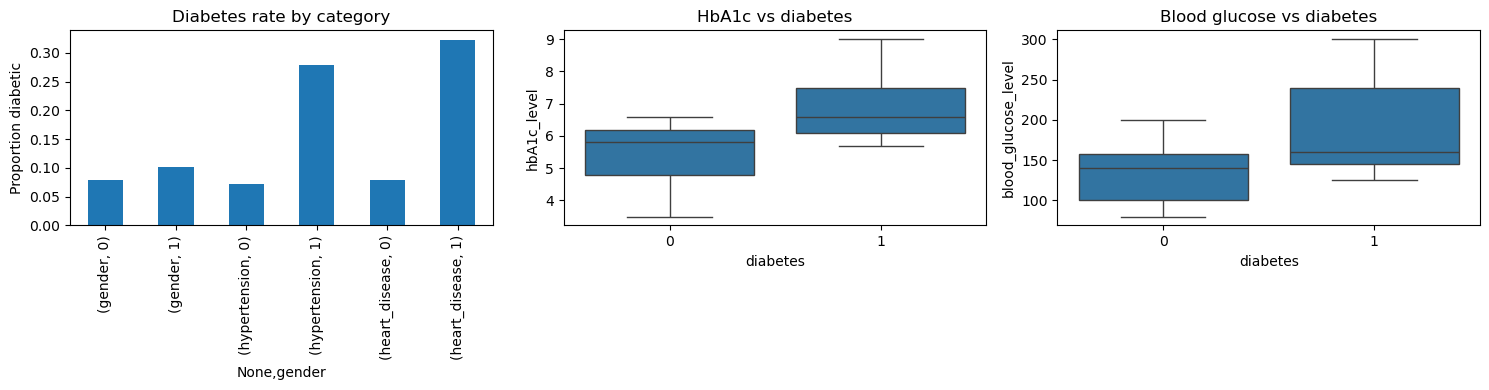

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rates = pd.concat({c: df1.groupby(c)['diabetes'].mean()
                   for c in ['gender', 'hypertension', 'heart_disease']})
rates.plot(kind='bar', ax=axes[0], title='Diabetes rate by category')
axes[0].set_ylabel('Proportion diabetic')

sns.boxplot(x='diabetes', y='hbA1c_level', data=df1, ax=axes[1])
axes[1].set_title('HbA1c vs diabetes')

sns.boxplot(x='diabetes', y='blood_glucose_level', data=df1, ax=axes[2])
axes[2].set_title('Blood glucose vs diabetes')

plt.tight_layout(); plt.show()

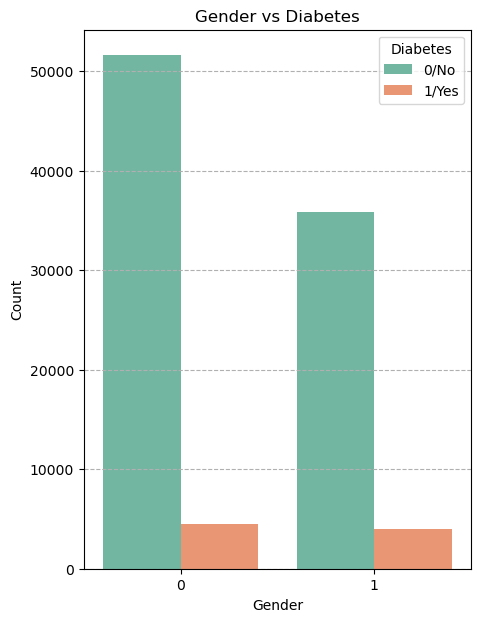

In [8]:
plt.figure(figsize=(5,7))
sns.countplot(x='gender', hue='diabetes', data=df1, palette='Set2')
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = df1.drop(columns=['diabetes'])
y = df1['diabetes']
feature_names = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Reset indices so .iloc in the CV loops lines up with the numpy arrays
y_train, y_val, y_test = [s.reset_index(drop=True) for s in (y_train, y_val, y_test)]

for name, s in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, len(s), "diabetic rate:", round(s.mean(), 4))

Train 67165 diabetic rate: 0.0884
Val 14392 diabetic rate: 0.0884
Test 14393 diabetic rate: 0.0884


In [10]:
def count_outliers(df, columns):
    out = {}
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[col] = int(((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum())
    return out

# Report only: HbA1c/glucose "outliers" are real diabetic readings, so they are NOT capped
print("IQR outliers (train):",
      count_outliers(X_train, ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']))

# Cap BMI only, using bounds from the training set
q1, q3 = X_train['bmi'].quantile([0.25, 0.75])
iqr = q3 - q1
bmi_low, bmi_high = q1 - 1.5*iqr, q3 + 1.5*iqr
for d in (X_train, X_val, X_test):
    d['bmi'] = d['bmi'].clip(bmi_low, bmi_high)
print(f"BMI capped to [{bmi_low:.2f}, {bmi_high:.2f}]")

IQR outliers (train): {'age': 0, 'bmi': 3634, 'hbA1c_level': 923, 'blood_glucose_level': 1407}
BMI capped to [13.62, 39.70]


In [11]:
from sklearn.preprocessing import MinMaxScaler

# Step 1: Initialize scaler
scaler = MinMaxScaler()

# Step 2: Fit on TRAINING data (before oversampling)
X_train = scaler.fit_transform(X_train)

# Step 3: Transform validation and test data
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [12]:
# Check min and max values
print("TRAIN MIN:", X_train.min())
print("TRAIN MAX:", X_train.max())

print("\nVALIDATION MIN:", X_val.min())
print("VALIDATION MAX:", X_val.max())

print("\nTEST MIN:", X_test.min())
print("TEST MAX:", X_test.max())

TRAIN MIN: 0.0
TRAIN MAX: 1.0

VALIDATION MIN: 0.0
VALIDATION MAX: 1.0

TEST MIN: 0.0
TEST MAX: 1.0


In [13]:
binary_idx = [feature_names.index(c) for c in ['gender', 'hypertension', 'heart_disease']]
smoke_idx  = [i for i, c in enumerate(feature_names) if c.startswith('smoking_')]

def fix_synthetic(X):
    X = np.asarray(X, dtype=float).copy()
    X[:, binary_idx] = np.round(X[:, binary_idx])
    s = X[:, smoke_idx]
    onehot = np.zeros_like(s)
    onehot[np.arange(len(s)), s.argmax(axis=1)] = 1
    X[:, smoke_idx] = onehot
    return X

In [14]:
pip install smote-variants

Note: you may need to restart the kernel to use updated packages.


In [15]:
!pip install torch


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\FaiMkri\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [16]:
!pip install pytorch-tabular


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\FaiMkri\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [17]:
pip install pytorch-tabnet

Note: you may need to restart the kernel to use updated packages.


In [18]:
pip install torch torchvision torchaudio

In [19]:
!pip install xgboost catboost


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\FaiMkri\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [20]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# ProWSyn will be applied inside each training fold during cross-validation.
X_train_meta = X_train
y_train_meta = y_train
X_test_meta = X_test
y_test_meta = y_test

print(f"Training data shape: {X_train_meta.shape}")
print(f"Training labels shape: {y_train_meta.shape}")
print(f"Test data shape: {X_test_meta.shape}")
print(f"Test labels shape: {y_test_meta.shape}")

Training data shape: (67165, 11)
Training labels shape: (67165,)
Test data shape: (14393, 11)
Test labels shape: (14393,)


In [ ]:
# CELL: DNN Training with Cross-Validation

import smote_variants as sv
from collections import Counter
from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.metrics import Recall

N_FOLDS = 5

# Initialize OOF, test and validation prediction arrays
oof_dnn = np.zeros(len(X_train_meta))
test_dnn = np.zeros(len(X_test_meta))
val_dnn = np.zeros(len(X_val))

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"DNN FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]              # NumPy array
    y_fold_train = y_train_meta.iloc[train_idx].copy()  # Pandas Series, positional indexing

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print(f"Fold train: {X_fold_train.shape}")
    print(f"Fold validation: {X_fold_val.shape}")
    print(f"Training class distribution after ProWSyn: {Counter(y_fold_train)}")

    # Build DNN model
    model_dnn = Sequential([
        Input(shape=(X_fold_train.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(64, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='tanh'),
        Dropout(0.25),
        Dense(16, activation='tanh'),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(4, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model_dnn.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', Recall(name='recall')]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    # Train
    history_dnn = model_dnn.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_dnn[val_idx] = model_dnn.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions (averaged over folds)
    test_dnn += model_dnn.predict(X_test_meta, verbose=0).ravel() / N_FOLDS
    val_dnn += model_dnn.predict(X_val, verbose=0).ravel() / N_FOLDS

print("\nDNN OOF, validation and test predictions completed!")

2026-09-30 14:17:58,753:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 14:17:58,755:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:17:58,761:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 1/5


2026-09-30 14:17:59,343:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:17:59,346:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:17:59,736:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:17:59,737:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:18:00,006:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:18:00,008:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:18:00,189:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:18:00,190:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:18:00,285:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:20:11,066:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:20:12,171:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:20:12,656:INFO:ProWSyn: simplex sampli

Fold train: (97964, 11)
Fold validation: (13433, 11)
Training class distribution after ProWSyn: Counter({np.int64(0): 48982, np.int64(1): 48982})
Epoch 1/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 3s 996us/step - accuracy: 0.8687 - loss: 0.3004 - recall: 0.9057 - val_accuracy: 0.8558 - val_loss: 0.2593 - val_recall: 0.9225
Epoch 2/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 2s 972us/step - accuracy: 0.8922 - loss: 0.2473 - recall: 0.9311 - val_accuracy: 0.8670 - val_loss: 0.2428 - val_recall: 0.9166
Epoch 3/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 853us/step - accuracy: 0.8951 - loss: 0.2382 - recall: 0.9322 - val_accuracy: 0.8670 - val_loss: 0.2423 - val_recall: 0.9309
Epoch 4/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 874us/step - accuracy: 0.8967 - loss: 0.2333 - recall: 0.9352 - val_accuracy: 0.8841 - val_loss: 0.2159 - val_recall: 0.9014
Epoch 5/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 869us/step - accuracy: 0.8976 - loss: 0.2291 - recall: 0.9330 - val_accuracy: 0.8826 - val_loss: 0.2138 - val_recall: 0.9284
Epoc

2026-09-30 14:20:45,707:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 14:20:45,711:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:20:45,721:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


...

2026-09-30 14:23:23,609:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:23:23,612:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:23:23,995:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:23:23,997:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:23:24,263:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:23:24,265:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:23:24,433:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:23:24,434:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:23:24,543:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:25:39,457:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:25:40,666:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 14:25:41,232:INFO:ProWSyn: simplex sampli

Fold train: (97964, 11)
Fold validation: (13433, 11)
Training class distribution after ProWSyn: Counter({np.int64(0): 48982, np.int64(1): 48982})
Epoch 1/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8668 - loss: 0.3126 - recall: 0.9011 - val_accuracy: 0.8424 - val_loss: 0.2905 - val_recall: 0.9495
Epoch 2/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 902us/step - accuracy: 0.8919 - loss: 0.2481 - recall: 0.9305 - val_accuracy: 0.8526 - val_loss: 0.2578 - val_recall: 0.9427
Epoch 3/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 886us/step - accuracy: 0.8955 - loss: 0.2357 - recall: 0.9312 - val_accuracy: 0.8819 - val_loss: 0.2226 - val_recall: 0.9225
Epoch 4/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 877us/step - accuracy: 0.8975 - loss: 0.2292 - recall: 0.9326 - val_accuracy: 0.8717 - val_loss: 0.2246 - val_recall: 0.9318
Epoch 5/40
1531/1531 ━━━━━━━━━━━━━━━━━━━━ 1s 881us/step - accuracy: 0.8987 - loss: 0.2262 - recall: 0.9342 - val_accuracy: 0.8746 - val_loss: 0.2267 - val_recall: 0.9377
Epoch 

2026-09-30 14:26:02,283:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 14:26:02,287:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:26:02,301:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 4/5


2026-09-30 14:26:02,870:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:26:02,873:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 14:26:03,252:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 14:26:03,254:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


In [ ]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, precision_recall_curve)

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

dnn_thr = best_threshold(y_val, val_dnn)          # chosen on VALIDATION
dnn_pred = (test_dnn >= dnn_thr).astype(int)      # applied to TEST (fold-averaged)

print(f"DNN Results (threshold = {dnn_thr:.3f}, chosen on validation)")
print(classification_report(y_test, dnn_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_dnn), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_dnn), 4))

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step
DNN Results, Classification Report
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.66      0.76      0.71      1275

    accuracy                           0.95     15000
   macro avg       0.82      0.86      0.84     15000
weighted avg       0.95      0.95      0.95     15000

ROC-AUC: 0.965876324154434
PR-AUC: 0.8382844730803025


In [ ]:
# CELL: TabNet Training with Cross-Validation

from pytorch_tabnet.tab_model import TabNetClassifier
import torch
import smote_variants as sv
from collections import Counter

# Initialize OOF, test and validation prediction arrays
oof_tabnet = np.zeros(len(X_train_meta))
test_tabnet = np.zeros(len(X_test_meta))
val_tabnet = np.zeros(len(X_val))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"TABNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = np.asarray(y_train_meta.iloc[val_idx])

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Validation shape: {X_fold_val.shape}")

    # Build model
    tabnet_model = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=7,
        gamma=1.5,
        lambda_sparse=1e-2,
        optimizer_fn=torch.optim.AdamW,
        optimizer_params=dict(lr=0.005),
        seed=SEED + fold,
        verbose=1
    )

    # Train
    tabnet_model.fit(
        X_fold_train,
        y_fold_train,
        eval_set=[(X_fold_val, y_fold_val)],
        eval_name=['val'],
        eval_metric=['auc'],
        max_epochs=50,
        patience=5,
        batch_size=1024,
        virtual_batch_size=128
    )

    # OOF prediction
    oof_tabnet[val_idx] = tabnet_model.predict_proba(X_fold_val)[:, 1]

    # Test and validation predictions (averaged over folds)
    test_tabnet += tabnet_model.predict_proba(X_test_meta)[:, 1] / N_FOLDS
    val_tabnet += tabnet_model.predict_proba(X_val)[:, 1] / N_FOLDS

print("\nTabNet OOF, validation and test predictions completed!")

2026-09-30 11:00:05,259:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 11:00:05,261:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:00:05,268:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



TABNET FOLD 1/5


2026-09-30 11:00:05,705:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:00:05,707:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:00:06,066:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:00:06,068:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:00:06,300:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:00:06,301:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:00:06,437:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:00:06,438:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:00:06,519:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:02:16,654:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:02:18,767:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:02:19,450:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.34368 | val_auc: 0.92599 |  0:00:04s
epoch 1  | loss: 0.2228  | val_auc: 0.94491 |  0:00:09s
epoch 2  | loss: 0.20409 | val_auc: 0.96473 |  0:00:14s
epoch 3  | loss: 0.19097 | val_auc: 0.96627 |  0:00:19s
epoch 4  | loss: 0.1764  | val_auc: 0.96699 |  0:00:24s
epoch 5  | loss: 0.17426 | val_auc: 0.96923 |  0:00:28s
epoch 6  | loss: 0.16385 | val_auc: 0.96661 |  0:00:33s
epoch 7  | loss: 0.15991 | val_auc: 0.97244 |  0:00:38s
epoch 8  | loss: 0.15157 | val_auc: 0.97056 |  0:00:43s
epoch 9  | loss: 0.15243 | val_auc: 0.97221 |  0:00:48s
epoch 10 | loss: 0.15013 | val_auc: 0.97093 |  0:00:52s
epoch 11 | loss: 0.14771 | val_auc: 0.97069 |  0:00:57s
epoch 12 | loss: 0.14721 | val_auc: 0.97168 |  0:01:02s

Early stopping occurred at epoch 12 with best_epoch = 7 and best_val_auc = 0.97244


2026-09-30 11:03:26,222:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 11:03:26,224:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:03:26,232:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


...

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.52318 | val_auc: 0.9231  |  0:00:04s
epoch 1  | loss: 0.2233  | val_auc: 0.93652 |  0:00:09s
epoch 2  | loss: 0.20403 | val_auc: 0.96118 |  0:00:14s
epoch 3  | loss: 0.19015 | val_auc: 0.96498 |  0:00:19s
epoch 4  | loss: 0.17815 | val_auc: 0.96787 |  0:00:23s
epoch 5  | loss: 0.17111 | val_auc: 0.96558 |  0:00:28s
epoch 6  | loss: 0.18013 | val_auc: 0.96685 |  0:00:33s
epoch 7  | loss: 0.17694 | val_auc: 0.96748 |  0:00:38s
epoch 8  | loss: 0.16442 | val_auc: 0.96803 |  0:00:42s
epoch 9  | loss: 0.16096 | val_auc: 0.96713 |  0:00:47s
epoch 10 | loss: 0.16009 | val_auc: 0.96904 |  0:00:52s
epoch 11 | loss: 0.15717 | val_auc: 0.96741 |  0:00:57s
epoch 12 | loss: 0.16044 | val_auc: 0.96977 |  0:01:01s
epoch 13 | loss: 0.15401 | val_auc: 0.96885 |  0:01:06s
epoch 14 | loss: 0.14597 | val_auc: 0.9724  |  0:01:11s
epoch 15 | loss: 0.14031 | val_auc: 0.96991 |  0:01:15s
epoch 16 | loss: 0.13594 

2026-09-30 11:14:49,431:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 11:14:49,433:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:14:49,443:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



TABNET FOLD 5/5


2026-09-30 11:14:49,939:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:14:49,942:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:14:50,316:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:14:50,318:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:14:50,553:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:14:50,555:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:14:50,691:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 11:14:50,692:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 11:14:50,763:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:17:04,107:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:17:05,837:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 11:17:06,442:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.38344 | val_auc: 0.89315 |  0:00:04s
epoch 1  | loss: 0.23194 | val_auc: 0.94913 |  0:00:09s
epoch 2  | loss: 0.21126 | val_auc: 0.9566  |  0:00:14s
epoch 3  | loss: 0.20512 | val_auc: 0.95852 |  0:00:19s
epoch 4  | loss: 0.20019 | val_auc: 0.96632 |  0:00:23s
epoch 5  | loss: 0.18973 | val_auc: 0.96914 |  0:00:28s
epoch 6  | loss: 0.17973 | val_auc: 0.96731 |  0:00:33s
epoch 7  | loss: 0.17427 | val_auc: 0.96715 |  0:00:38s
epoch 8  | loss: 0.16937 | val_auc: 0.96928 |  0:00:42s
epoch 9  | loss: 0.1657  | val_auc: 0.97073 |  0:00:47s
epoch 10 | loss: 0.15823 | val_auc: 0.9694  |  0:00:52s
epoch 11 | loss: 0.15646 | val_auc: 0.96733 |  0:00:57s
epoch 12 | loss: 0.15329 | val_auc: 0.97273 |  0:01:01s
epoch 13 | loss: 0.14934 | val_auc: 0.97128 |  0:01:06s
epoch 14 | loss: 0.14602 | val_auc: 0.97239 |  0:01:11s
epoch 15 | loss: 0.14574 | val_auc: 0.96944 |  0:01:16s
epoch 16 | loss: 0.14457 

In [ ]:
tabnet_thr = best_threshold(y_val, val_tabnet)          # chosen on VALIDATION
tabnet_pred = (test_tabnet >= tabnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"TabNet Results (threshold = {tabnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, tabnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_tabnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_tabnet), 4))

Tabnet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96     13725
           1       0.58      0.81      0.68      1275

    accuracy                           0.93     15000
   macro avg       0.78      0.88      0.82     15000
weighted avg       0.95      0.93      0.94     15000

ROC-AUC: 0.9698688667452409
PR-AUC: 0.8457056027958185


In [ ]:
# CELL: ResNet (tabular, with residual connections) Training with Cross-Validation

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from collections import Counter
import smote_variants as sv


def build_resnet(n_features, width=64, n_blocks=3, dropout=0.2):
    inp = layers.Input(shape=(n_features,))
    x = layers.Dense(width)(inp)
    for _ in range(n_blocks):
        h = layers.BatchNormalization()(x)
        h = layers.Dense(width * 2, activation='relu')(h)
        h = layers.Dropout(dropout)(h)
        h = layers.Dense(width)(h)
        x = layers.Add()([x, h])          # skip (residual) connection
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return Model(inp, out)


# Initialize OOF, test and validation prediction arrays
oof_resnet = np.zeros(len(X_train_meta))
test_resnet = np.zeros(len(X_test_meta))
val_resnet = np.zeros(len(X_val))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"RESNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Validation shape: {X_fold_val.shape}")

    # Build model
    resnet_model = build_resnet(X_fold_train.shape[1])

    resnet_model.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history = resnet_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=100,
        batch_size=1024,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_resnet[val_idx] = resnet_model.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions (averaged over folds)
    test_resnet += resnet_model.predict(X_test_meta, verbose=0).ravel() / N_FOLDS
    val_resnet += resnet_model.predict(X_val, verbose=0).ravel() / N_FOLDS

print("\nResNet OOF, validation and test predictions completed!")

In [ ]:
resnet_thr = best_threshold(y_val, val_resnet)          # chosen on VALIDATION
resnet_pred = (test_resnet >= resnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"ResNet Results (threshold = {resnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, resnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_resnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_resnet), 4))

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 284us/step
ResNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.97      0.97     13725
           1       0.69      0.78      0.73      1275

    accuracy                           0.95     15000
   macro avg       0.84      0.88      0.85     15000
weighted avg       0.96      0.95      0.95     15000

ROC-AUC: 0.9730971534697668
PR-AUC: 0.8653905730473096


In [ ]:
print(f"Fold {fold} completed.")

Fold 5 completed.


In [ ]:
# CELL: XGBoost base model with Cross-Validation
# Tree models handle the 91/9 imbalance fine, so this one trains on the ORIGINAL fold data (no ProWSyn).
# It sees the data differently from the neural nets, which is what the ensemble needs.

from xgboost import XGBClassifier

oof_xgb = np.zeros(len(X_train_meta))
test_xgb = np.zeros(len(X_test_meta))
val_xgb = np.zeros(len(X_val))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    xgb_base = XGBClassifier(
        n_estimators=600,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=SEED
    )
    xgb_base.fit(X_train_meta[train_idx], y_train_meta.iloc[train_idx])

    oof_xgb[val_idx] = xgb_base.predict_proba(X_train_meta[val_idx])[:, 1]
    test_xgb += xgb_base.predict_proba(X_test_meta)[:, 1] / N_FOLDS
    val_xgb += xgb_base.predict_proba(X_val)[:, 1] / N_FOLDS
    print(f"XGBoost fold {fold}/{N_FOLDS} done")

xgb_thr = best_threshold(y_val, val_xgb)
xgb_base_pred = (test_xgb >= xgb_thr).astype(int)

print(f"XGBoost Results (threshold = {xgb_thr:.3f}, chosen on validation)")
print(classification_report(y_test, xgb_base_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_xgb), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_xgb), 4))


In [ ]:
# Meta-features

from sklearn.preprocessing import StandardScaler


# DNN + TabNet
X_meta_dt_train = np.column_stack([oof_dnn, oof_tabnet])
X_meta_dt_test = np.column_stack([test_dnn, test_tabnet])

scaler_dt = StandardScaler()
X_meta_dt_train_scaled = scaler_dt.fit_transform(X_meta_dt_train)
X_meta_dt_test_scaled = scaler_dt.transform(X_meta_dt_test)


# DNN + ResNet
X_meta_dr_train = np.column_stack([oof_dnn, oof_resnet])
X_meta_dr_test = np.column_stack([test_dnn, test_resnet])

scaler_dr = StandardScaler()
X_meta_dr_train_scaled = scaler_dr.fit_transform(X_meta_dr_train)
X_meta_dr_test_scaled = scaler_dr.transform(X_meta_dr_test)


# TabNet + ResNet
X_meta_tr_train = np.column_stack([oof_tabnet, oof_resnet])
X_meta_tr_test = np.column_stack([test_tabnet, test_resnet])

scaler_tr = StandardScaler()
X_meta_tr_train_scaled = scaler_tr.fit_transform(X_meta_tr_train)
X_meta_tr_test_scaled = scaler_tr.transform(X_meta_tr_test)


# DNN + TabNet + ResNet
X_meta_all_train = np.column_stack([
    oof_dnn,
    oof_tabnet,
    oof_resnet
])

X_meta_all_test = np.column_stack([
    test_dnn,
    test_tabnet,
    test_resnet
])

scaler_all = StandardScaler()
X_meta_all_train_scaled = scaler_all.fit_transform(X_meta_all_train)
X_meta_all_test_scaled = scaler_all.transform(X_meta_all_test)

In [ ]:
from catboost import CatBoostClassifier


# DNN + TabNet
catboost_dt = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dt.fit(
    X_meta_dt_train,
    y_train
)

catboost_dt_prob = catboost_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

catboost_dt_pred = (catboost_dt_prob >= 0.5).astype(int)



# DNN + ResNet
catboost_dr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dr.fit(
    X_meta_dr_train,
    y_train
)

catboost_dr_prob = catboost_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

catboost_dr_pred = (catboost_dr_prob >= 0.5).astype(int)



# TabNet + ResNet
catboost_tr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_tr.fit(
    X_meta_tr_train,
    y_train
)

catboost_tr_prob = catboost_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

catboost_tr_pred = (catboost_tr_prob >= 0.5).astype(int)



# DNN + TabNet + ResNet
catboost_all = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_all.fit(
    X_meta_all_train,
    y_train
)

catboost_all_prob = catboost_all.predict_proba(
    X_meta_all_test
)[:, 1]

catboost_all_pred = (catboost_all_prob >= 0.5).astype(int)

In [ ]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
catboost_dt_results = {
    'Model': 'CatBoost: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, catboost_dt_pred),
    'Precision': precision_score(y_test, catboost_dt_pred),
    'Recall': recall_score(y_test, catboost_dt_pred),
    'F1': f1_score(y_test, catboost_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dt_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dt_prob)
}


# DNN + ResNet
catboost_dr_results = {
    'Model': 'CatBoost: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_dr_pred),
    'Precision': precision_score(y_test, catboost_dr_pred),
    'Recall': recall_score(y_test, catboost_dr_pred),
    'F1': f1_score(y_test, catboost_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dr_prob)
}

# TabNet + ResNet
catboost_tr_results = {
    'Model': 'CatBoost: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_tr_pred),
    'Precision': precision_score(y_test, catboost_tr_pred),
    'Recall': recall_score(y_test, catboost_tr_pred),
    'F1': f1_score(y_test, catboost_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_tr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_tr_prob)
}


# DNN + TabNet + ResNet
catboost_all_results = {
    'Model': 'CatBoost: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_all_pred),
    'Precision': precision_score(y_test, catboost_all_pred),
    'Recall': recall_score(y_test, catboost_all_pred),
    'F1': f1_score(y_test, catboost_all_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_all_prob),
    'PR-AUC': average_precision_score(y_test, catboost_all_prob)
}

# Combine Results

catboost_results = pd.DataFrame([
    catboost_dt_results,
    catboost_dr_results,
    catboost_tr_results,
    catboost_all_results
])

catboost_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,CatBoost: DNN + TabNet,0.970267,0.989374,0.657255,0.789821,0.974733,0.870129
1,CatBoost: DNN + ResNet,0.971800,0.997664,0.669804,0.801502,0.973853,0.868206
2,CatBoost: TabNet + ResNet,0.971867,1.000000,0.669020,0.801692,0.975236,0.872208
3,CatBoost: DNN + TabNet + ResNet,0.972000,0.998833,0.671373,0.803002,0.975239,0.873085


In [ ]:
from xgboost import XGBClassifier


# DNN + TabNet
xgb_dt = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dt.fit(
    X_meta_dt_train,
    y_train
)

xgb_dt_prob = xgb_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

xgb_dt_pred = (xgb_dt_prob >= 0.5).astype(int)



# DNN + ResNet
xgb_dr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dr.fit(
    X_meta_dr_train,
    y_train
)

xgb_dr_prob = xgb_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

xgb_dr_pred = (xgb_dr_prob >= 0.5).astype(int)


# TabNet + ResNet
xgb_tr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_tr.fit(
    X_meta_tr_train,
    y_train
)

xgb_tr_prob = xgb_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

xgb_tr_pred = (xgb_tr_prob >= 0.5).astype(int)


# DNN + TabNet + ResNet
xgb_all = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_all.fit(
    X_meta_all_train,
    y_train
)

xgb_all_prob = xgb_all.predict_proba(
    X_meta_all_test
)[:, 1]

xgb_all_pred = (xgb_all_prob >= 0.5).astype(int)

In [ ]:
# Evaluate 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
xgb_dt_results = {
    'Model': 'XGBoost: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, xgb_dt_pred),
    'Precision': precision_score(y_test, xgb_dt_pred),
    'Recall': recall_score(y_test, xgb_dt_pred),
    'F1': f1_score(y_test, xgb_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dt_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dt_prob)
}

# DNN + ResNet
xgb_dr_results = {
    'Model': 'XGBoost: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_dr_pred),
    'Precision': precision_score(y_test, xgb_dr_pred),
    'Recall': recall_score(y_test, xgb_dr_pred),
    'F1': f1_score(y_test, xgb_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dr_prob)
}

# TabNet + ResNet
xgb_tr_results = {
    'Model': 'XGBoost: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_tr_pred),
    'Precision': precision_score(y_test, xgb_tr_pred),
    'Recall': recall_score(y_test, xgb_tr_pred),
    'F1': f1_score(y_test, xgb_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_tr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_tr_prob)
}

# DNN + TabNet + ResNet
xgb_all_results = {
    'Model': 'XGBoost: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_all_pred),
    'Precision': precision_score(y_test, xgb_all_pred),
    'Recall': recall_score(y_test, xgb_all_pred),
    'F1': f1_score(y_test, xgb_all_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_all_prob),
    'PR-AUC': average_precision_score(y_test, xgb_all_prob)
}

# Combined Results
xgb_results = pd.DataFrame([
    xgb_dt_results,
    xgb_dr_results,
    xgb_tr_results,
    xgb_all_results
])

xgb_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost: DNN + TabNet,0.970333,0.989387,0.658039,0.790391,0.973718,0.868092
1,XGBoost: DNN + ResNet,0.971600,1.000000,0.665882,0.799435,0.972975,0.865224
2,XGBoost: TabNet + ResNet,0.971867,1.000000,0.669020,0.801692,0.974611,0.870096
3,XGBoost: DNN + TabNet + ResNet,0.971600,0.996491,0.668235,0.800000,0.974716,0.872006


In [ ]:
from sklearn.linear_model import LogisticRegression


# DNN + TabNet
lr_dt = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dt.fit(
    X_meta_dt_train_scaled,
    y_train
)

lr_dt_prob = lr_dt.predict_proba(
    X_meta_dt_test_scaled
)[:, 1]

lr_dt_pred = (lr_dt_prob >= 0.5).astype(int)



# DNN + ResNet
lr_dr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dr.fit(
    X_meta_dr_train_scaled,
    y_train
)

lr_dr_prob = lr_dr.predict_proba(
    X_meta_dr_test_scaled
)[:, 1]

lr_dr_pred = (lr_dr_prob >= 0.5).astype(int)



# TabNet + ResNet
lr_tr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tr.fit(
    X_meta_tr_train_scaled,
    y_train
)

lr_tr_prob = lr_tr.predict_proba(
    X_meta_tr_test_scaled
)[:, 1]

lr_tr_pred = (lr_tr_prob >= 0.5).astype(int)


# DNN + TabNet + ResNet
lr_all = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_all.fit(
    X_meta_all_train_scaled,
    y_train
)

lr_all_prob = lr_all.predict_proba(
    X_meta_all_test_scaled
)[:, 1]

lr_all_pred = (lr_all_prob >= 0.5).astype(int)

In [ ]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
lr_dt_results = {
    'Model': 'Logistic Regression: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, lr_dt_pred),
    'Precision': precision_score(y_test, lr_dt_pred),
    'Recall': recall_score(y_test, lr_dt_pred),
    'F1': f1_score(y_test, lr_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dt_prob),
    'PR-AUC': average_precision_score(y_test, lr_dt_prob)
}

# DNN + ResNet
lr_dr_results = {
    'Model': 'Logistic Regression: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, lr_dr_pred),
    'Precision': precision_score(y_test, lr_dr_pred),
    'Recall': recall_score(y_test, lr_dr_pred),
    'F1': f1_score(y_test, lr_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dr_prob),
    'PR-AUC': average_precision_score(y_test, lr_dr_prob)
}

# TabNet + ResNet
lr_tr_results = {
    'Model': 'Logistic Regression: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, lr_tr_pred),
    'Precision': precision_score(y_test, lr_tr_pred),
    'Recall': recall_score(y_test, lr_tr_pred),
    'F1': f1_score(y_test, lr_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_tr_prob),
    'PR-AUC': average_precision_score(y_test, lr_tr_prob)
}

# DNN + TabNet + ResNet
lr_all_results = {
    'Model': 'Logistic Regression: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, lr_all_pred),
    'Precision': precision_score(y_test, lr_all_pred),
    'Recall': recall_score(y_test, lr_all_pred),
    'F1': f1_score(y_test, lr_all_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_all_prob),
    'PR-AUC': average_precision_score(y_test, lr_all_prob)
}

# Combined Results
lr_results = pd.DataFrame([
    lr_dt_results,
    lr_dr_results,
    lr_tr_results,
    lr_all_results
])

lr_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression: DNN + TabNet,0.968867,0.912245,0.701176,0.792905,0.974526,0.868709
1,Logistic Regression: DNN + ResNet,0.968867,0.914784,0.698824,0.792352,0.973842,0.867419
2,Logistic Regression: TabNet + ResNet,0.969133,0.916838,0.700392,0.794131,0.974894,0.871312
3,Logistic Regression: DNN + TabNet + ResNet,0.969133,0.918557,0.698824,0.793764,0.974804,0.871002


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping


# DNN + TabNet
stacked_dnn_dt = Sequential([
    Input(shape=(X_meta_dt_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dt.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dt = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dt.fit(
    X_meta_dt_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dt],
    verbose=1
)

stacked_dnn_dt_prob = stacked_dnn_dt.predict(
    X_meta_dt_test_scaled
).ravel()

stacked_dnn_dt_pred = (
    stacked_dnn_dt_prob >= 0.5
).astype(int)



# DNN + ResNet
stacked_dnn_dr = Sequential([
    Input(shape=(X_meta_dr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dr.fit(
    X_meta_dr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dr],
    verbose=1
)

stacked_dnn_dr_prob = stacked_dnn_dr.predict(
    X_meta_dr_test_scaled
).ravel()

stacked_dnn_dr_pred = (
    stacked_dnn_dr_prob >= 0.5
).astype(int)



# TabNet + ResNet
stacked_dnn_tr = Sequential([
    Input(shape=(X_meta_tr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_tr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_tr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_tr.fit(
    X_meta_tr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_tr],
    verbose=1
)

stacked_dnn_tr_prob = stacked_dnn_tr.predict(
    X_meta_tr_test_scaled
).ravel()

stacked_dnn_tr_pred = (
    stacked_dnn_tr_prob >= 0.5
).astype(int)



# DNN + TabNet + ResNet
stacked_dnn_all = Sequential([
    Input(shape=(X_meta_all_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_all.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_all = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_all.fit(
    X_meta_all_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_all],
    verbose=1
)

stacked_dnn_all_prob = stacked_dnn_all.predict(
    X_meta_all_test_scaled
).ravel()

stacked_dnn_all_pred = (
    stacked_dnn_all_prob >= 0.5
).astype(int)

Epoch 1/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 722us/step - accuracy: 0.9520 - loss: 0.1545 - val_accuracy: 0.9649 - val_loss: 0.0997
Epoch 2/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 610us/step - accuracy: 0.9671 - loss: 0.1004 - val_accuracy: 0.9670 - val_loss: 0.0980
Epoch 3/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 611us/step - accuracy: 0.9678 - loss: 0.0989 - val_accuracy: 0.9671 - val_loss: 0.0972
Epoch 4/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 603us/step - accuracy: 0.9679 - loss: 0.0986 - val_accuracy: 0.9673 - val_loss: 0.0968
Epoch 5/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 623us/step - accuracy: 0.9681 - loss: 0.0965 - val_accuracy: 0.9675 - val_loss: 0.0961
Epoch 6/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 632us/step - accuracy: 0.9682 - loss: 0.0966 - val_accuracy: 0.9677 - val_loss: 0.0962
Epoch 7/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 721us/step - accuracy: 0.9684 - loss: 0.0956 - val_accuracy: 0.9671 - val_loss: 0.0966
Epoch 8/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 666us/step - accuracy: 0.9683 - loss: 0

In [ ]:
# Evaluate 

# DNN + TabNet
stacked_dnn_dt_results = {
    'Model': 'Stacked DNN: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_dt_pred),
    'Precision': precision_score(y_test, stacked_dnn_dt_pred),
    'Recall': recall_score(y_test, stacked_dnn_dt_pred),
    'F1': f1_score(y_test, stacked_dnn_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dt_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dt_prob)
}

# DNN + ResNet
stacked_dnn_dr_results = {
    'Model': 'Stacked DNN: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_dr_pred),
    'Precision': precision_score(y_test, stacked_dnn_dr_pred),
    'Recall': recall_score(y_test, stacked_dnn_dr_pred),
    'F1': f1_score(y_test, stacked_dnn_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dr_prob)
}

# TabNet + ResNet
stacked_dnn_tr_results = {
    'Model': 'Stacked DNN: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_tr_pred),
    'Precision': precision_score(y_test, stacked_dnn_tr_pred),
    'Recall': recall_score(y_test, stacked_dnn_tr_pred),
    'F1': f1_score(y_test, stacked_dnn_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_tr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_tr_prob)
}

# DNN: DNN + TabNet + ResNet
stacked_dnn_all_results = {
    'Model': 'Stacked DNN: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_all_pred),
    'Precision': precision_score(y_test, stacked_dnn_all_pred),
    'Recall': recall_score(y_test, stacked_dnn_all_pred),
    'F1': f1_score(y_test, stacked_dnn_all_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_all_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_all_prob)
}

# Combined
stacked_dnn_results = pd.DataFrame([
    stacked_dnn_dt_results,
    stacked_dnn_dr_results,
    stacked_dnn_tr_results,
    stacked_dnn_all_results
])

stacked_dnn_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Stacked DNN: DNN + TabNet,0.969333,0.997558,0.640784,0.780325,0.974942,0.870337
1,Stacked DNN: DNN + ResNet,0.971467,1.000000,0.664314,0.798303,0.974045,0.868879
2,Stacked DNN: TabNet + ResNet,0.972067,1.000000,0.671373,0.803379,0.975198,0.872528
3,Stacked DNN: DNN + TabNet + ResNet,0.971867,0.995354,0.672157,0.802434,0.975196,0.872611


In [ ]:
# CELL: Final ensemble
# Idea taken from HiTCLe (Shaheen et al., 2024): the meta-model gets the base predictions
# together with the original features, so it can learn where each base model is reliable.
# DNN is left out: it is the weakest model and adds nothing that ResNet/TabNet do not already give.

from catboost import CatBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report)


def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


final_bases = {
    'TabNet': (oof_tabnet, val_tabnet, test_tabnet),
    'ResNet': (oof_resnet, val_resnet, test_resnet),
    'XGBoost': (oof_xgb, val_xgb, test_xgb),
}

X_meta_final_train = np.column_stack([to_logit(o) for o, v, t in final_bases.values()] + [X_train_meta])
X_meta_final_val = np.column_stack([to_logit(v) for o, v, t in final_bases.values()] + [X_val])
X_meta_final_test = np.column_stack([to_logit(t) for o, v, t in final_bases.values()] + [X_test_meta])

final_meta = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    verbose=False,
    random_seed=SEED
)
final_meta.fit(X_meta_final_train, y_train_meta)

final_val_prob = final_meta.predict_proba(X_meta_final_val)[:, 1]
final_prob = final_meta.predict_proba(X_meta_final_test)[:, 1]

final_thr = best_threshold(y_val, final_val_prob)       # chosen on VALIDATION
final_pred = (final_prob >= final_thr).astype(int)      # applied to TEST

final_results = pd.DataFrame([{
    'Model': 'CatBoost + features: TabNet + ResNet + XGBoost',
    'Accuracy': accuracy_score(y_test, final_pred),
    'Precision': precision_score(y_test, final_pred),
    'Recall': recall_score(y_test, final_pred),
    'F1': f1_score(y_test, final_pred),
    'ROC-AUC': roc_auc_score(y_test, final_prob),
    'PR-AUC': average_precision_score(y_test, final_prob)
}])

print(f"Final ensemble (threshold = {final_thr:.3f}, chosen on validation)")
print(classification_report(y_test, final_pred, digits=4))
final_results


In [ ]:
# DNN Results

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dnn_prob = model_dnn.predict(X_test).ravel()
dnn_pred = (dnn_prob > 0.5).astype(int)

dnn_results = pd.DataFrame([{
    'Model': 'DNN',
    'Base Models': 'DNN',
    'Accuracy': accuracy_score(y_test, dnn_pred),
    'Precision': precision_score(y_test, dnn_pred),
    'Recall': recall_score(y_test, dnn_pred),
    'F1': f1_score(y_test, dnn_pred),
    'ROC-AUC': roc_auc_score(y_test, dnn_prob),
    'PR-AUC': average_precision_score(y_test, dnn_prob)
}])

print("DNN Results")
print(classification_report(y_test, dnn_pred))
print(dnn_results)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step
DNN Results
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.66      0.76      0.71      1275

    accuracy                           0.95     15000
   macro avg       0.82      0.86      0.84     15000
weighted avg       0.95      0.95      0.95     15000

  Model Base Models  Accuracy  Precision    Recall        F1   ROC-AUC  \
0   DNN         DNN    0.9468   0.663918  0.757647  0.707692  0.965876   

     PR-AUC  
0  0.838284  


In [ ]:
# TabNet Results

tabnet_prob = tabnet_model.predict_proba(X_test)[:, 1]
tabnet_pred = (tabnet_prob > 0.5).astype(int)

print("TabNet Results, Classification Report:\n")
print(classification_report(y_test, tabnet_pred))

print("ROC-AUC:", roc_auc_score(y_test, tabnet_prob))
print("PR-AUC:", average_precision_score(y_test, tabnet_prob))

tabnet_results = pd.DataFrame([{
    'Model': 'TabNet',
    'Base Models': 'TabNet',
    'Accuracy': accuracy_score(y_test, tabnet_pred),
    'Precision': precision_score(y_test, tabnet_pred),
    'Recall': recall_score(y_test, tabnet_pred),
    'F1': f1_score(y_test, tabnet_pred),
    'ROC-AUC': roc_auc_score(y_test, tabnet_prob),
    'PR-AUC': average_precision_score(y_test, tabnet_prob)
}])

tabnet_results

TabNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96     13725
           1       0.58      0.81      0.68      1275

    accuracy                           0.93     15000
   macro avg       0.78      0.88      0.82     15000
weighted avg       0.95      0.93      0.94     15000

ROC-AUC: 0.9698688667452409
PR-AUC: 0.8457056027958185


,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,TabNet,TabNet,0.934867,0.584755,0.806275,0.677877,0.969869,0.845706


In [ ]:
# ResNet Results

resnet_prob = resnet_model.predict(X_test).ravel()
resnet_pred = (resnet_prob > 0.5).astype(int)

print("ResNet Results, Classification Report:\n")
print(classification_report(y_test, resnet_pred))

print("ROC-AUC:", roc_auc_score(y_test, resnet_prob))
print("PR-AUC:", average_precision_score(y_test, resnet_prob))

resnet_results = pd.DataFrame([{
    'Model': 'ResNet',
    'Base Models': 'ResNet',
    'Accuracy': accuracy_score(y_test, resnet_pred),
    'Precision': precision_score(y_test, resnet_pred),
    'Recall': recall_score(y_test, resnet_pred),
    'F1': f1_score(y_test, resnet_pred),
    'ROC-AUC': roc_auc_score(y_test, resnet_prob),
    'PR-AUC': average_precision_score(y_test, resnet_prob)
}])

resnet_results

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 337us/step
ResNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.97      0.97     13725
           1       0.69      0.78      0.73      1275

    accuracy                           0.95     15000
   macro avg       0.84      0.88      0.85     15000
weighted avg       0.96      0.95      0.95     15000

ROC-AUC: 0.9730971534697668
PR-AUC: 0.8653905730473096


,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,ResNet,ResNet,0.951733,0.690394,0.783529,0.734019,0.973097,0.865391


In [ ]:
# Summary of Base Models + Meta-Learners

all_results = pd.concat([
    dnn_results,
    tabnet_results,
    resnet_results,
    catboost_results,
    xgb_results,
    lr_results,
    stacked_dnn_results
], ignore_index=True)

all_results

,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,DNN,DNN,0.946800,0.663918,0.757647,0.707692,0.965876,0.838284
1,TabNet,TabNet,0.934867,0.584755,0.806275,0.677877,0.969869,0.845706
2,ResNet,ResNet,0.951733,0.690394,0.783529,0.734019,0.973097,0.865391
3,CatBoost: DNN + TabNet,NaN,0.970267,0.989374,0.657255,0.789821,0.974733,0.870129
4,CatBoost: DNN + ResNet,NaN,0.971800,0.997664,0.669804,0.801502,0.973853,0.868206
5,CatBoost: TabNet + ResNet,NaN,0.971867,1.000000,0.669020,0.801692,0.975236,0.872208
6,CatBoost: DNN + TabNet + ResNet,NaN,0.972000,0.998833,0.671373,0.803002,0.975239,0.873085
7,XGBoost: DNN + TabNet,NaN,0.970333,0.989387,0.658039,0.790391,0.973718,0.868092
8,XGBoost: DNN + ResNet,NaN,0.971600,1.000000,0.665882,0.799435,0.972975,0.865224
9,XGBoost: TabNet + ResNet,NaN,0.971867,1.000000,0.669020,0.801692,0.974611,0.870096


In [ ]:
!pip install shap

  Using cached shap-0.52.0-cp312-abi3-win_amd64.whl.metadata (26 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.52.0-cp312-abi3-win_amd64.whl (499 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 362.3 kB/s et


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\FaiMkri\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import shap

# Background samples for Kernel SHAP
background = shap.sample(X_train_meta, 100, random_state=42)

# Test samples to explain
X_sample = shap.sample(X_test_meta, 200, random_state=42)

# Explain probability of the diabetic class (class = 1)
explainer = shap.KernelExplainer(
    lambda x: tabnet_model.predict_proba(x)[:, 1],
    background
)

# Compute SHAP values
shap_values = explainer.shap_values(X_sample)

# Check output
print("SHAP type:", type(shap_values))
print("SHAP shape:", np.array(shap_values).shape)
print("X_sample shape:", X_sample.shape)

  0%|          | 0/200 [00:00<?, ?it/s]

SHAP type: <class 'numpy.ndarray'>
SHAP shape: (200, 8)
X_sample shape: (200, 8)


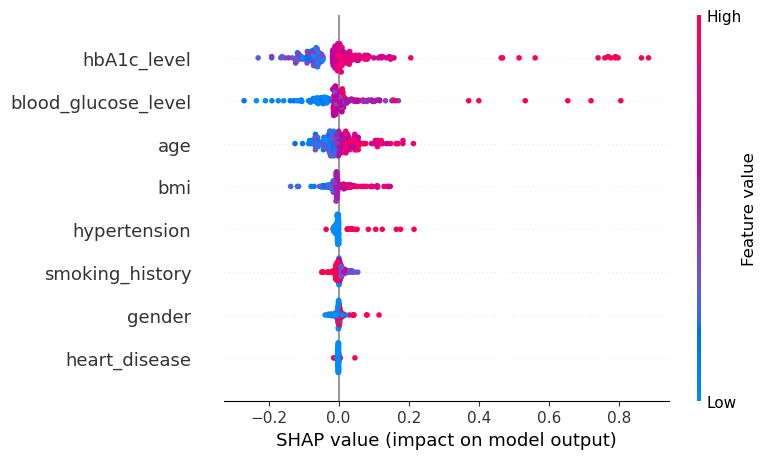

In [ ]:
# If SHAP returns a 3D array (samples, features, classes)
if len(np.array(shap_values).shape) == 3:
    shap_diabetes = shap_values[:, :, 1]   # Class 1 = diabetic

# If SHAP returns a list (older SHAP versions)
elif isinstance(shap_values, list):
    shap_diabetes = shap_values[1]

# Already a 2D array
else:
    shap_diabetes = shap_values

# Summary plot
shap.summary_plot(
    shap_diabetes,
    X_sample,
    feature_names=X.columns.tolist()
)

In [ ]:
import numpy as np

# Predict probabilities from the stacked TaReDNet model
stack_probs = stack_dnn.predict(X_meta_test, verbose=0).ravel()

# Convert probabilities to binary class labels
y_pred = (stack_probs >= 0.5).astype(int)

print("stack_probs shape:", stack_probs.shape)
print("y_pred shape:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])

stack_probs shape: (15000,)
y_pred shape: (15000,)
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


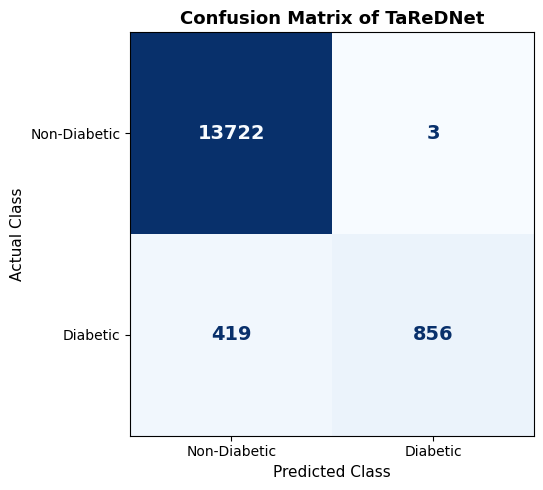

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5.5, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False,
    values_format="d"
)

# Improve formatting for IEEE paper
ax.set_title("Confusion Matrix of TaReDNet", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Class", fontsize=11)
ax.set_ylabel("Actual Class", fontsize=11)

# Increase font size of numbers inside the cells
for text in ax.texts:
    text.set_fontsize(14)
    text.set_fontweight("bold")

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "Figure_4_Confusion_Matrix_TaReDNet.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()